<a href="https://colab.research.google.com/github/240264-sudo/AI-ML-lab/blob/main/AI_ML_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Understanding Gradient Descent

Gradient descent is an optimization algorithm used to minimize a function. To find a local minimum of a function using gradient descent, one takes steps proportional to the negative of the gradient (or approximate gradient) of the function at the current point. If steps are taken in the positive direction of the gradient, one approaches a local maximum of that function; this is then known as gradient ascent.

In simple terms, think of yourself standing on a mountain (representing the function's surface) and wanting to reach the lowest point (the minimum). You'd look around, find the steepest downward slope, and take a step in that direction. You repeat this process until you can't go down any further. That's essentially what gradient descent does mathematically.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# For reproducibility
np.random.seed(42)

### Define the function and its gradient

Let's use a simple quadratic function `f(x) = x^2`. The goal of gradient descent will be to find the minimum of this function, which is at `x=0`.

In [ ]:
# Define the function to minimize (e.g., f(x) = x^2)
def f(x):
    return x**2

# Define the derivative (gradient) of the function (e.g., f'(x) = 2x)
def df(x):
    return 2 * x

### Gradient Descent Algorithm

Here's the core of the gradient descent algorithm. We start at an initial point, and then iteratively update our position by moving in the opposite direction of the gradient, scaled by a learning rate.

In [ ]:
def gradient_descent(start_x, learning_rate, num_iterations):
    x_history = [start_x]
    cost_history = [f(start_x)]

    for _ in range(num_iterations):
        # Calculate the gradient
        gradient = df(x_history[-1])

        # Update x
        new_x = x_history[-1] - learning_rate * gradient
        x_history.append(new_x)
        cost_history.append(f(new_x))

    return np.array(x_history), np.array(cost_history)

# Parameters for gradient descent
initial_x = 4.0 # Starting point
learning_rate = 0.1 # How big of a step to take
iterations = 50 # Number of steps

x_values, cost_values = gradient_descent(initial_x, learning_rate, iterations)

### Animate Gradient Descent

Now, let's visualize how the gradient descent algorithm progresses over time. The animation will show the function, the path taken by the `x` value, and how the cost decreases with each iteration.

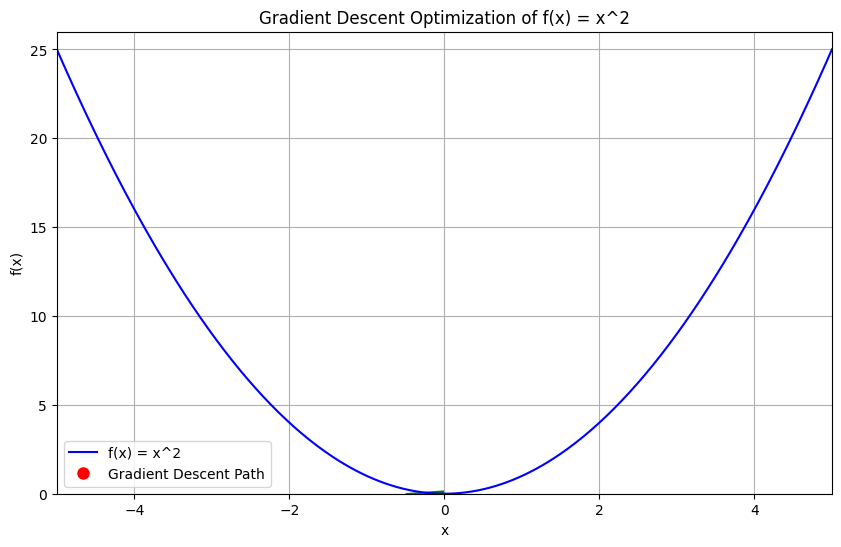

In [ ]:
# Create the figure and axis for the plot
fig, ax = plt.subplots(figsize=(10, 6))

# Generate x values for the function curve
x_func = np.linspace(-5, 5, 400)
y_func = f(x_func)

# Plot the function curve
ax.plot(x_func, y_func, label='f(x) = x^2', color='blue')

# Initialize the point that will move
point, = ax.plot([], [], 'o', color='red', markersize=8, label='Gradient Descent Path')

# Initialize current_arrow_artist to None. It will be created/recreated in update.
current_arrow_artist = None

# Set plot limits and labels
ax.set_xlim(-5, 5)
ax.set_ylim(0, 26) # Slightly above 4^2 = 16
ax.set_xlabel('x')
ax.set_ylabel('f(x)')
ax.set_title('Gradient Descent Optimization of f(x) = x^2')
ax.legend()
ax.grid(True)

def init():
    point.set_data([], [])
    # We are managing the arrow dynamically, so no initial arrow to return here.
    return point, # Return point, as it's modified in place

def update(frame):
    global current_arrow_artist # Declare current_arrow_artist as global

    # Update the position of the point
    current_x = x_values[frame]
    current_y = f(current_x)
    point.set_data([current_x], [current_y])

    # Remove the previous arrow if it exists
    if current_arrow_artist:
        current_arrow_artist.remove()

    # Calculate the gradient and arrow parameters
    grad_direction = -df(current_x)
    arrow_scale = 0.5
    dx = arrow_scale * grad_direction

    # Create a new arrow for the current frame
    current_arrow_artist = ax.arrow(current_x, current_y, dx, 0, head_width=0.3, head_length=0.5, fc='green', ec='green', alpha=1)

    # Return modified artists. For blit=False, this is less strict, but still good practice.
    return [point, current_arrow_artist]

# Create the animation with blit=False
ani = FuncAnimation(fig, update, frames=len(x_values), init_func=init, interval=100, repeat=False, blit=False)

# Display the animation in Colab
HTML(ani.to_jshtml())